In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [5]:
import sys
print(sys.executable)

/Users/teste/.venv/bin/python


In [7]:
import os
print(os.getcwd())

/Users/teste/Desktop/sentiment-analysis-app/notebooks


In [8]:
df = pd.read_csv("../data/IMDB Dataset.csv")

df.head()

,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive
2,I thought this was a wonderful way to spend ti...,positive
3,Basically there's a family where a little boy ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive


In [11]:
df.shape

(50000, 2)

In [12]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   review     50000 non-null  object
 1   sentiment  50000 non-null  object
dtypes: object(2)
memory usage: 781.4+ KB


In [13]:
df.isnull().sum()

review       0
sentiment    0
dtype: int64

In [14]:
df.duplicated().sum()

np.int64(418)

In [15]:
df["review"].duplicated().sum()

np.int64(418)

In [ ]:
df = df.drop_duplicates(subset = ["review"]).reset_index(drop=True)

In [17]:
print("Dataset shape:", df.shape)
print("Remaining duplicates:", df["review"].duplicated().sum())

Dataset shape: (49582, 2)
Remaining duplicates: 0


In [18]:
df["sentiment"].value_counts()

sentiment
positive    24884
negative    24698
Name: count, dtype: int64

In [19]:
df["sentiment"].value_counts(normalize = True) * 100

sentiment
positive    50.187568
negative    49.812432
Name: proportion, dtype: float64

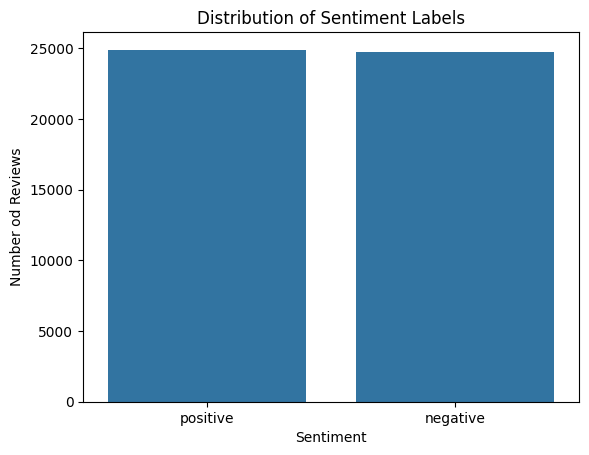

In [21]:
sns.countplot(data = df, x = "sentiment")
plt.title("Distribution of Sentiment Labels")
plt.xlabel("Sentiment")
plt.ylabel("Number od Reviews")
plt.show()

In [22]:
df["review_length"] = df["review"].apply(lambda x: len(x.split()))
df[["review", "review_length"]].head()

,review,review_length
0,One of the other reviewers has mentioned that ...,307
1,A wonderful little production. <br /><br />The...,162
2,I thought this was a wonderful way to spend ti...,166
3,Basically there's a family where a little boy ...,138
4,"Petter Mattei's ""Love in the Time of Money"" is...",230


In [23]:
df["review_length"].describe()

count    49582.000000
mean       231.350167
std        171.542020
min          4.000000
25%        126.000000
50%        173.000000
75%        281.000000
max       2470.000000
Name: review_length, dtype: float64

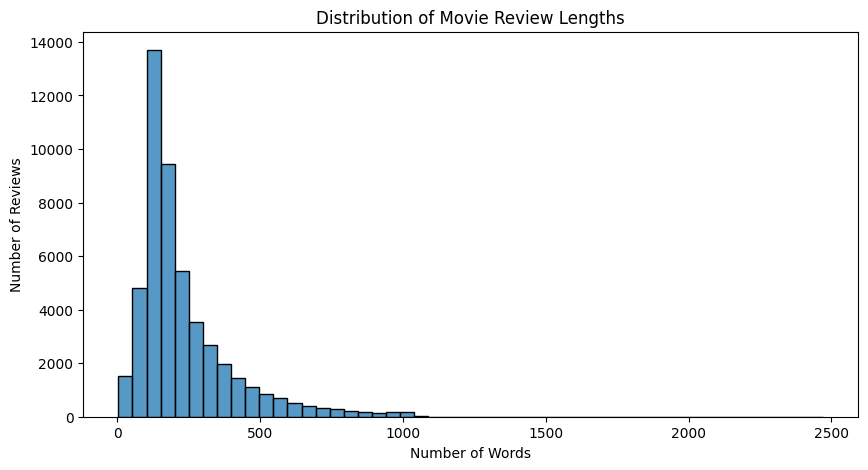

In [24]:
plt.figure(figsize=(10, 5))

sns.histplot(data = df, x = "review_length", bins = 50)

plt.title("Distribution of Movie Review Lengths")
plt.xlabel("Number of Words")
plt.ylabel("Number of Reviews")

plt.show()

In [25]:
import re 
import html

def clean_text(text):
    # Convert HTML entities into readable characters
    text = html.unescape(text)

    #Remove HTML tags
    text = re.sub(r"<[^>]+>", " ", text)

    # Convert text to lowercase
    text = text.lower()

    #Replace repeated whitespace with a singçe space
    text = re.sub(r"\s+", " ", text).strip()

    return text

In [27]:
sample = "This movie was NOt good!!! <br /><br /> I hated it."

clean_text(sample)

'this movie was not good!!! i hated it.'

In [28]:
df["cleaned_review"] = df["review"].apply(clean_text)

df[["review", "cleaned_review"]].head()

,review,cleaned_review
0,One of the other reviewers has mentioned that ...,one of the other reviewers has mentioned that ...
1,A wonderful little production. <br /><br />The...,a wonderful little production. the filming tec...
2,I thought this was a wonderful way to spend ti...,i thought this was a wonderful way to spend ti...
3,Basically there's a family where a little boy ...,basically there's a family where a little boy ...
4,"Petter Mattei's ""Love in the Time of Money"" is...","petter mattei's ""love in the time of money"" is..."


In [29]:
print("Original review:")
print(df["review"].iloc[0][:500])

print("\nCleaned_review:")
print(df["cleaned_review"].iloc[0][:500])

Original review:
One of the other reviewers has mentioned that after watching just 1 Oz episode you'll be hooked. They are right, as this is exactly what happened with me.<br /><br />The first thing that struck me about Oz was its brutality and unflinching scenes of violence, which set in right from the word GO. Trust me, this is not a show for the faint hearted or timid. This show pulls no punches with regards to drugs, sex or violence. Its is hardcore, in the classic use of the word.<br /><br />It is called OZ

Cleaned_review:
one of the other reviewers has mentioned that after watching just 1 oz episode you'll be hooked. they are right, as this is exactly what happened with me. the first thing that struck me about oz was its brutality and unflinching scenes of violence, which set in right from the word go. trust me, this is not a show for the faint hearted or timid. this show pulls no punches with regards to drugs, sex or violence. its is hardcore, in the classic use of the word. it

In [30]:
print("Original word count:",
      len(df["review"].iloc[0].split()))

print("Cleaned word count:",
      len(df["cleaned_review"].iloc[0].split()))

Original word count: 307
Cleaned word count: 304


In [35]:
from sklearn.model_selection import train_test_split

train_idx, test_idx = train_test_split(
    df.index,
    test_size = 0.2,
    random_state = 42,
    stratify = df["sentiment"]
)

In [37]:
train_df = df.loc[train_idx].copy()
test_df = df.loc[test_idx].copy()

print("Training reviews:", len(train_df))
print("Testing reviews:", len(test_df))

Training reviews: 39665
Testing reviews: 9917


In [38]:
print("Training sentiment distribution:")
print(train_df["sentiment"].value_counts(normalize = True))

print("\nTesting sentiment distribution:")
print(test_df["sentiment"].value_counts(normalize = True))

Training sentiment distribution:
sentiment
positive    0.501878
negative    0.498122
Name: proportion, dtype: float64

Testing sentiment distribution:
sentiment
positive    0.501865
negative    0.498135
Name: proportion, dtype: float64


In [39]:
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

model_a = Pipeline([
    ("tfidf", TfidfVectorizer()),
    ("classifier", LogisticRegression(max_iter = 1000))
])

In [42]:
X_train_a = train_df["review"]
y_train = train_df["sentiment"]

model_a.fit(X_train_a, y_train)

Pipeline(steps=[('tfidf', TfidfVectorizer()),
                ('classifier', LogisticRegression(max_iter=1000))])

In [43]:
X_test_a = test_df["review"]
y_test = test_df["sentiment"]


predictions_a = model_a.predict(X_test_a)

print("First 10 predictions:")
print(predictions_a[:10])

print("\nFrist 10 actual sentiments:")
print(y_test.iloc[:10].values)

First 10 predictions:
['negative' 'positive' 'positive' 'negative' 'negative' 'positive'
 'negative' 'negative' 'positive' 'negative']

Frist 10 actual sentiments:
['negative' 'positive' 'positive' 'negative' 'negative' 'positive'
 'negative' 'negative' 'positive' 'negative']


In [44]:
from sklearn.metrics import accuracy_score


accuracy_a = accuracy_score(y_test, predictions_a)


print(f"Model A Accuracy: {accuracy_a: .2%}")

Model A Accuracy:  89.71%


In [45]:
from sklearn.metrics import classification_report

print(classification_report(y_test, predictions_a))

              precision    recall  f1-score   support

    negative       0.91      0.88      0.90      4940
    positive       0.89      0.91      0.90      4977

    accuracy                           0.90      9917
   macro avg       0.90      0.90      0.90      9917
weighted avg       0.90      0.90      0.90      9917



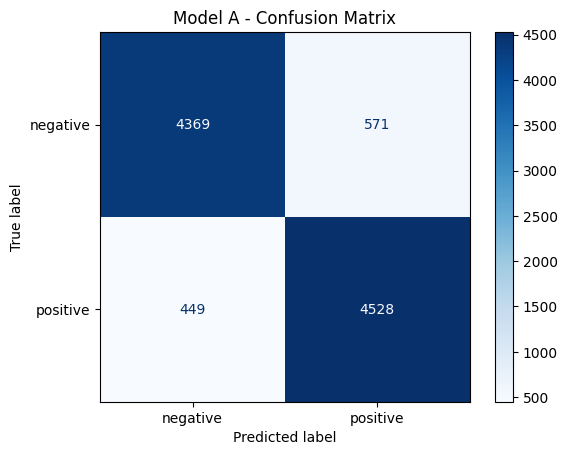

In [51]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt


ConfusionMatrixDisplay.from_predictions(
    y_test,
    predictions_a,
    labels = ["negative", "positive"],
    cmap = "Blues",
    values_format = "d"
)

plt.title("Model A - Confusion Matrix")
plt.show()